# Week 5 Thursday

Our primary goal today is to see an example of overfitting with a too flexible neural network.

## The dataset

Here is the same dataset as from Tuesday.

In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

In [2]:
digits = load_digits()

In [3]:
X = digits.data
X_rescale = X / X.max()
y = digits.target

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X_rescale, y, test_size=0.25, random_state=210)

* Corrupt our training data by setting the first 350 labels to be `1`.

In [5]:
X_train.shape

(1347, 64)

In [8]:
y_train[:350] = 1

* Display the element at position `6` in `X_train` using `ax.imshow` and check its label.

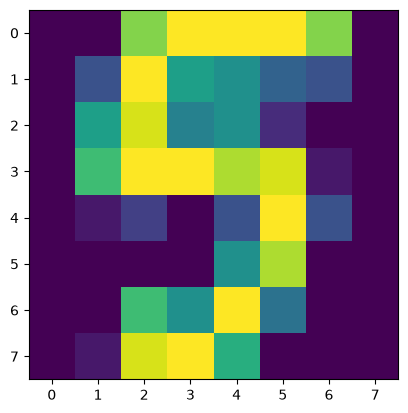

In [6]:
fig, ax = plt.subplots()
ax.imshow(X_train[6].reshape((8,8)))

In [9]:
y_train[6]

np.int64(1)

## Logistic Regression

* For comparison with the more flexible model below, fit a logistic regression model on the training data.  Set `max_iter` to be `1000`, so that more time is spent seeking the best coefficients in this model.
* What training score do we get?
* What would a baseline score be on our (uncorrupted) dataset?
* What test score do we get?
* How many parameters get learned when we call `fit`?  You can use the `size` attribute to get the number of elements in a NumPy array.  Do you see where these numbers come from, in terms of the function in logistic regression?

In [11]:
from sklearn.linear_model import LogisticRegression

In [12]:
clf = LogisticRegression(max_iter=1000)

In [13]:
clf.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [14]:
clf.score(X_train, y_train)

0.7312546399406088

In [15]:
clf.score(X_test, y_test)

0.8244444444444444

In [17]:
clf.coef_.size

640

In [18]:
clf.intercept_.size

10

When we run `clf.fit` in this case, we're learning 640+10 parameters.

## Learning

[3Blue1Brown video](https://www.youtube.com/watch?v=IHZwWFHWa-w) on gradient descent.  Recommended clips.

* [0:25-1:24](https://youtu.be/IHZwWFHWa-w?si=Mr29oTledAbooqNT&t=25)
* [3:18-4:05](https://youtu.be/IHZwWFHWa-w?si=VjLDxWp93Jzw8G2u&t=198)
* [5:15-8:16](https://youtu.be/IHZwWFHWa-w?si=854I6w8FXce1DQvG&t=315)

## A flexible neural network

* (Side comment.  The next homework will be a regression problem, not a classification problem, so the relevant class there will be `MLPRegressor.)
* Instantiate a neural network with two hidden layers, each with 128 neurons.
* Use ReLU for our activation function and stochastic gradient descent for our solver.
* Set the `random_state` to `15` so we all get the same results.
* Set `max_iter` to `1000` for now (we will do more later).
* How do our training and test scores look here?

In [19]:
from sklearn.neural_network import MLPClassifier

In [20]:
clf = MLPClassifier(
    hidden_layer_sizes=(128,128),
    activation="relu",
    solver="sgd",
    random_state=15,
    max_iter=1000
)

In [21]:
clf.fit(X_train, y_train)

/workspaces/AISCI210-Unit2-NN1/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(128, ...)"
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'sgd'
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",1000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",15
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [22]:
clf.score(X_train, y_train)

0.7624350408314774

In [23]:
clf.score(X_test, y_test)

0.8533333333333334

* How many parameters got learned by this process?
* Can you reproduce that number yourself, by looking at the structure of the neural network?

In [24]:
64*128+128*128+128*10

25856

In [25]:
type(clf.coefs_)

list

In [27]:
len(clf.coefs_)

3

In [29]:
s = 0
for c in clf.coefs_:
    s += c.size
s

25856

In [30]:
sum(c.size for c in clf.coefs_)

25856

In [31]:
sum(c.size for c in clf.intercepts_)

266

In [32]:
clf.coefs_[1].size

16384

* Let's now instantiate a new Neural Network Classifier.  Begin the same settings as above.
* Remove the `max_iter` value.
* Set `learning_rate_init` to `0.003`.
* Set `momentum` to `0.9`.
* Set `batch_size` to be as big as possible.
* Set `alpha` to be `0` (this removes a regularization penalty which seeks to prevent coefficients from becoming too big).

In [34]:
clf = MLPClassifier(
    hidden_layer_sizes=(128,128),
    activation="relu",
    solver="sgd",
    random_state=15,
    learning_rate_init=0.003,
    momentum=0.9,
    batch_size=len(X_train),
    alpha=0
)

Rather than using a `score`, we will use `log_loss`, which is a more refined measure.  Unlike with `score`, with loss functions a lower score is better.

* Import `log_loss` from `sklearn.metrics`.
* Define two empty lists, `train_loss` and `test_loss`.
* Rather than using `fit`, use `partial_fit`.  For this you must also specify `classes=digits.target_names`.
* Record the training log loss and the test log loss for each of 14,000 epochs (decrease if that is too much for Codespace).  The syntax is `log_loss(true_values, probs, labels=digits.target_names)`.
* Plot these two loss values on the same axes.  Use `label` so you know which is which.
* Can you detect overfitting?

In [35]:
from sklearn.metrics import log_loss

In [36]:
digits.target_names

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

0
1000
2000
3000
4000
5000
6000
7000
8000
9000
10000
11000
12000
13000


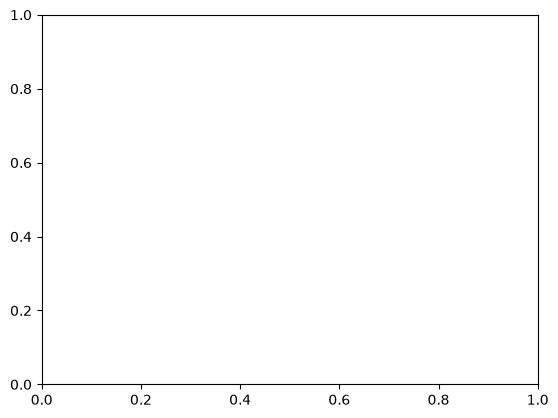

In [39]:
fig, ax = plt.subplots()

clf = MLPClassifier(
    hidden_layer_sizes=(128,128),
    activation="relu",
    solver="sgd",
    random_state=15,
    learning_rate_init=0.003,
    momentum=0.9,
    batch_size=len(X_train),
    alpha=0
)

train_loss = []
test_loss = []

for i in range(14000):
    if i%1000 == 0:
        print(i)
    clf.partial_fit(X_train, y_train, classes=digits.target_names)
    train_loss.append(log_loss(
        y_train,
        clf.predict_proba(X_train)
    ))
    test_loss.append(log_loss(
        y_test,
        clf.predict_proba(X_test)
    ))


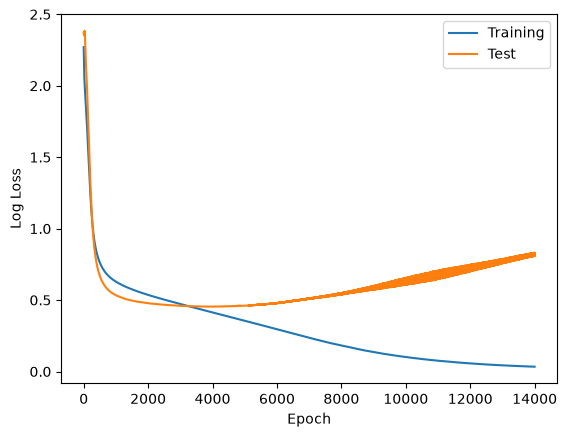

In [40]:
fig, ax = plt.subplots()
ax.plot(train_loss, label="Training")
ax.plot(test_loss, label="Test")
ax.set_xlabel("Epoch")
ax.set_ylabel("Log Loss")
ax.legend()